In [1]:
#Import numerical libraries
from mpmath.math2 import sqrt2
from scipy.integrate import solve_ivp
from matplotlib import pyplot as plt
import numpy as np

### **Numerical setup and Model definitions**

In [2]:
#Model 1
class QuadraticPotential:
    def __init__(self,m :float):
        self.m : float = m
    
    def V(self, phi: float) -> float:    #Potential
        return self.m**2 * phi**2 / 2.0
    
    def Vprime(self,phi:float) -> float:   #Derivative of potential
        return self.m**2 *phi

In [3]:
#Model 2
class QuarticPotential:
    def __init__(self, g: float):
        self.g: float = g

    def V(self, phi: float) -> float:     #Potential
        return self.g * phi**4 / 24.0

    def Vprime(self, phi: float) -> float:    #Derivative of potential
        return self.g * phi**3 / 6.0

In [4]:
#Define backround equations
def ode_rhs(N: float, y, model):
    phi: float = y[0]   #Extract field variables
    pi: float = y[1]

    V: float = model.V(phi) #Evaluate potential terms
    Vprime: float = model.Vprime(phi)

    epsilon: float = (pi**2)/2 #Compute slow-roll parameter
    Hsquare: float = V/(3.0-epsilon) #Compute Hubble parameter

    phi_rhs = pi #Field evolution equations
    pi_rhs = -(3.0 - epsilon)*pi - (Vprime/Hsquare)
    
    return [phi_rhs, pi_rhs]

### **Quadratic potential full numerical methods**

In [19]:
#Conditions for end of inflation: Stop integration at epsilon=1
def inflation_end_event(N, y, model):
    phi: float = y[0]
    pi: float = y[1]

    V: float = model.V(phi)
    Vprime: float = model.Vprime(phi)

    epsilon: float = (pi**2)/2 #Compute slow-roll parameter
    Hsquare: float = V/(3.0-epsilon)

    return epsilon - 1.0 #Define termination condition

#Mark terminal event
inflation_end_event.terminal = True
inflation_end_event.direction = 0

#Select an inflationary model
model = QuadraticPotential(m=1e-5)

#Solve field evolution numerically
sol = solve_ivp(
    ode_rhs,
    t_span=(0, 500),
    y0=(20.0, 0.0),
    args=(model,),
    events=inflation_end_event,
    dense_output=True,
    atol=1e-8,
    rtol=1e-8,

)

#Extract values at the end of inflation
N_end = sol.t_events[0][0]
phi_end = sol.y_events[0][0][0]
pi_end  = sol.y_events[0][0][1]

print("Inflation ends at N =", N_end)
print("phi_end =", phi_end)
print("pi_end =", pi_end)

epsilon_end = 0.5 * float(pi_end)**2
V_end = model.V(float(phi_end))
denominator_end = 3.0 - epsilon_end
if denominator_end <= 0:
    raise ValueError(f"Denominator 3 - ε <= 0 at end: {denominator_end}")
H2_end = V_end / denominator_end
H_end = np.sqrt(H2_end) #Evaluate the final Hubble scale

print(f"  epsilon_end = {epsilon_end:.6g}")
print(f"  H_end = {H_end:.6g}")


Inflation ends at N = 100.9679445555777
phi_end = 1.0093427025881776
pi_end = -1.414213562373076
  epsilon_end = 1
  H_end = 5.04671e-06


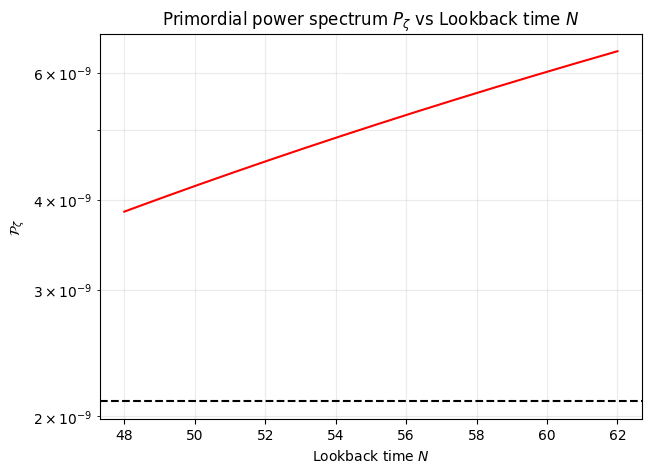

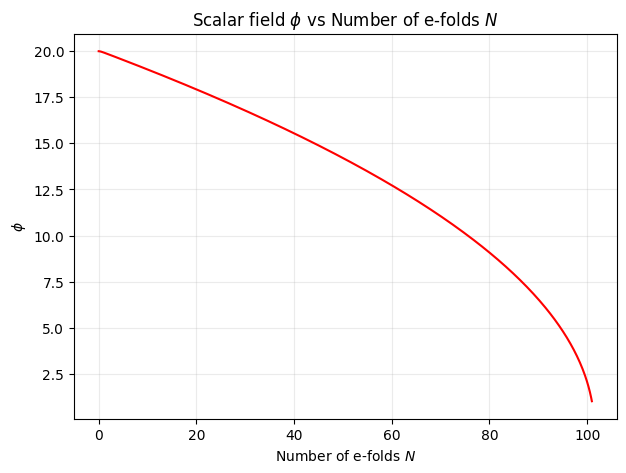

In [20]:
#Sample e-fold range
N_vals = np.linspace(N_end-62,N_end-48, 1000)
P_zeta_vals = [] #Store power spectrum values

#Evaluate spectrum at each point
for N in N_vals:
    phi, pi = sol.sol(N)
    phi = float(phi)
    pi = float(pi)

    epsilon = 0.5 * pi**2  #Compute slow-roll parameter
    if epsilon <= 0:
        P_zeta_vals.append(np.nan)
        continue

    V = model.V(phi)
    denom = 3.0 - epsilon
    if denom <= 0:
        P_zeta_vals.append(np.nan)
        continue

    H2 = V / denom
    P_zeta = H2 / (8.0 * np.pi**2 * epsilon)  #Compute curvature spectrum
    P_zeta_vals.append(P_zeta)

A_s= np.exp(3.044)/10**10

plt.rcParams["text.usetex"] = False
plt.figure(figsize=(7,5))  #Plot primordial spectrum
plt.semilogy(N_end - N_vals, P_zeta_vals,color='red')
plt.axhline(A_s, linestyle='--',color='black')
plt.xlabel(r"Lookback time $N$")
plt.ylabel(r"$\mathcal{P}_\zeta$")
plt.title(r'Primordial power spectrum $P_\zeta$ vs Lookback time $N$')
plt.grid(True, which='both', alpha=0.25)
plt.savefig("P_zeta_Quadratic.pdf")

plt.show()



plt.figure(figsize=(7,5))
plt.plot(sol.t,sol.y[:1].T,color='red')  #Plot phi(t)
plt.xlabel("Number of e-folds $N$")
plt.ylabel("$\phi$")
plt.title(r'Scalar field $\phi$ vs Number of e-folds $N$')
plt.grid(True, which='both', alpha=0.25)
plt.savefig("Phi_Quadratic.pdf")
plt.show()

6.42752193701e-09
3.8482195467e-09


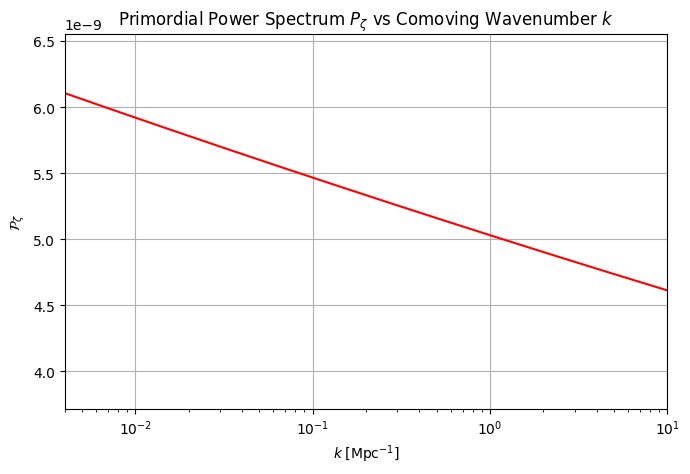

k_vals min, max: 0.0008498087048574673 898.8003931980013
n_s (at N_end-50) = 0.95951393
n_s (at N_end-60) = 0.96630745


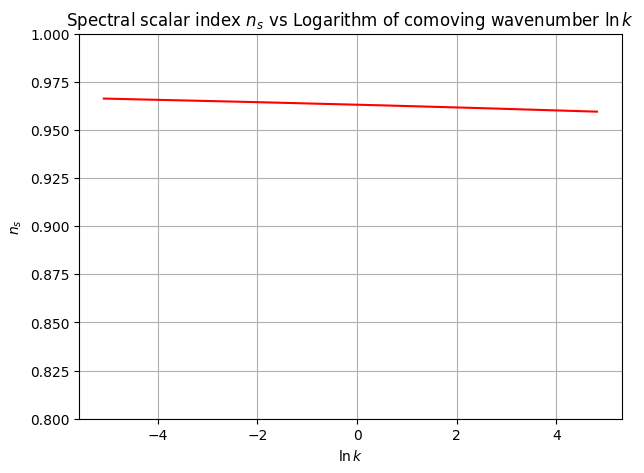

In [21]:
P_zeta_vals = np.array(P_zeta_vals)
N_vals = np.linspace(N_end-62,N_end-48,1000)  #40 < N_vals < 50

print(f"{P_zeta_vals[0]:.12g}")
print(f"{P_zeta_vals[-1]:.12g}")

#Define constants+units
Mp = 1

SqrtG = (1/np.sqrt(8*np.pi)) * 1/Mp
meter = SqrtG/(1.61625518e-35)
kelvin = (1/SqrtG)/1.41678417e32
TCMB= 2.72548*kelvin
pc = 3.086e16 * meter
Mpc = pc * 10**6
m= 1e-5 * Mp
V_end = 1/2 * m**2 * phi_end**2

#Extract values for phi, pi at each sample point in the time grid
phis, pis = sol.sol(N_vals)

#Compute epsilon and V_cmb at each sample point in the time grid
m2 = m * m
epsilons = np.empty_like(N_vals)
Vs = np.empty_like(N_vals)
lnk = np.empty_like(N_vals)

pi2 = np.pi * np.pi
matching_eq_const_piece = (
        + (1/4.0) * np.log(pi2/135.0)
        + np.log(Mpc*Mp)
        + np.log(TCMB/Mp)
)

#Compute comoving wavenumber
for i in range(0, len(N_vals)):
    N_val = N_vals[i]

    phi = phis[i]
    pi = pis[i]

    phi2 = phi*phi
    pi2 = pi*pi

    epsilon = pi2 / (2.0 * Mp**2)
    V = (1.0/2.0) * m2 * phi2

    epsilons[i] = epsilon
    Vs[i] = V

    lnk[i] = (
        -(N_end-N_val)
        + matching_eq_const_piece
        + 1/4.0 * np.log((V/Mp**4)/(1.0-(epsilon/3.0)))
        + 1/4.0 * np.log((V/V_end) * (2.0/3.0)/(1.0-(epsilon/3.0)))
)

#k_vals here measured in 1/Mpc, Convert log-scale to k
k_vals = np.exp(lnk)


plt.figure(figsize=(7,5))
plt.plot(k_vals, P_zeta_vals,color='red')  #Plot p_zeta(k)
plt.xlabel(r'$k\;[\mathrm{Mpc}^{-1}]$')
plt.ylabel(r'$\mathcal{P}_\zeta$')
plt.title(r'Primordial Power Spectrum $P_\zeta$ vs Comoving Wavenumber $k$')
plt.grid(True)
plt.xscale("log")
#plt.yscale("log")
plt.xlim((0.004,10))
plt.tight_layout()
plt.savefig("Pzeta_vs_k_Quadratic.pdf")
plt.show()


print("k_vals min, max:", np.min(k_vals), np.max(k_vals))

lnk = np.log(k_vals)
lnP = np.log(P_zeta_vals)

#Sort data for spline fit
idx = np.argsort(lnk)

lnk_sorted = lnk[idx]
lnP_sorted = lnP[idx]

from scipy.interpolate import make_interp_spline

#Construct interpolation spline
spline = make_interp_spline(lnk_sorted, lnP_sorted, k=3) #needs x-values to be increasing in order

#Differentiate logarithmic spectrum
spline_deriv = spline.derivative()

#Select an observable window
mask = (N_vals >= N_end-60) & (N_vals <= N_end-50) 

lnk_region = lnk[mask]
ns_region = 1.0 + spline_deriv(lnk_region) #Compute scalar spectral index

print(f"n_s (at N_end-50) = {ns_region[-1]:.8g}")
print(f"n_s (at N_end-60) = {ns_region[0]:.8g}")

plt.figure(figsize=(7,5))

plt.plot(lnk_region, ns_region,color='red')  #Plot lnk vs ns

plt.xlabel(r'$\ln k$')
plt.ylabel(r'$n_s$')
plt.title('Spectral scalar index $n_s$ vs Logarithm of comoving wavenumber $\ln k$')

plt.ylim(0.8,1.0)

plt.grid(True)
plt.savefig("ns_vs_k_Quadratic.pdf")
plt.show()

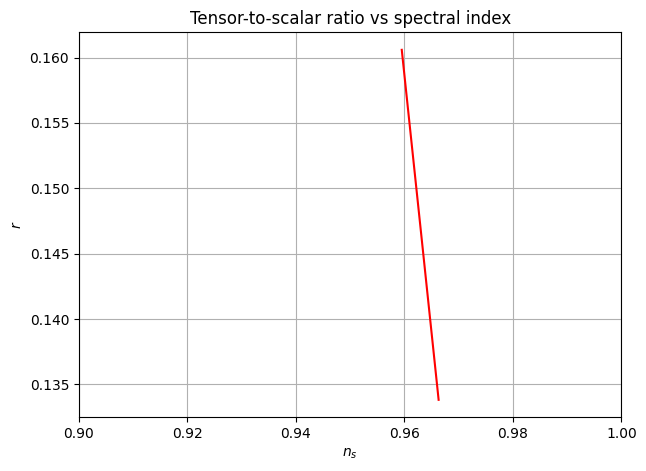

In [22]:
#Evaluate tensor-to-scalar ratio
phi_vals, pi_vals = sol.sol(N_vals)
epsilon_vals = pi_vals**2 / (2 * Mp**2)
r_vals = 16 * epsilon_vals

#Restrict r_vals to the observable window
mask = (N_vals >= N_end-60) & (N_vals <= N_end-50)

r_region = r_vals[mask]

#Plot numerical trajectory
plt.figure(figsize=(7,5))

plt.plot(ns_region, r_region,color='red')

plt.xlabel(r'$n_s$')
plt.ylabel(r'$r$')
plt.title('Tensor-to-scalar ratio vs spectral index')
plt.xlim(0.9,1.0)
plt.grid(True)
plt.show()


### **Quartic potential full numerical methods**


In [11]:
#Conditions for end of inflation: Stop integration at epsilon=1
def inflation_end_event(N, y, model):
    phi: float = y[0]
    pi: float = y[1]

    V: float = model.V(phi)
    Vprime: float = model.Vprime(phi)

    epsilon: float = (pi**2)/2  #Compute slow-roll parameter
    Hsquare: float = V/(3.0-epsilon)

    return epsilon - 1.0 #Define termination condition

#Mark terminal event
inflation_end_event.terminal = True
inflation_end_event.direction = 0

#Select an inflationary model
model = QuarticPotential(g=1e-14)

#Solve field evolution numerically
sol = solve_ivp(
    ode_rhs,
    t_span=(0, 500),
    y0=(25.0, 0.0),
    args=(model,),
    events=inflation_end_event,
    dense_output=True,
    atol=1e-10,
    rtol=1e-12,

)

#Extract values at the end of inflation
N_end = sol.t_events[0][0]
phi_end = sol.y_events[0][0][0]
pi_end  = sol.y_events[0][0][1]

print("Inflation ends at N =", N_end)
print("phi_end =", phi_end)
print("pi_end =", pi_end)

epsilon_end = 0.5 * float(pi_end)**2
V_end = model.V(float(phi_end))
denominator_end = 3.0 - epsilon_end
if denominator_end <= 0:
    raise ValueError(f"Denominator 3 - ε <= 0 at end: {denominator_end}")
H2_end = V_end / denominator_end
H_end = np.sqrt(H2_end)  #Evaluate the final Hubble scale

print(f"  epsilon_end = {epsilon_end:.6g}")
print(f"  H_end = {H_end:.6g}")

Inflation ends at N = 78.53368859960324
phi_end = 2.3393837962177915
pi_end = -1.414213562373097
  epsilon_end = 1
  H_end = 7.89919e-08


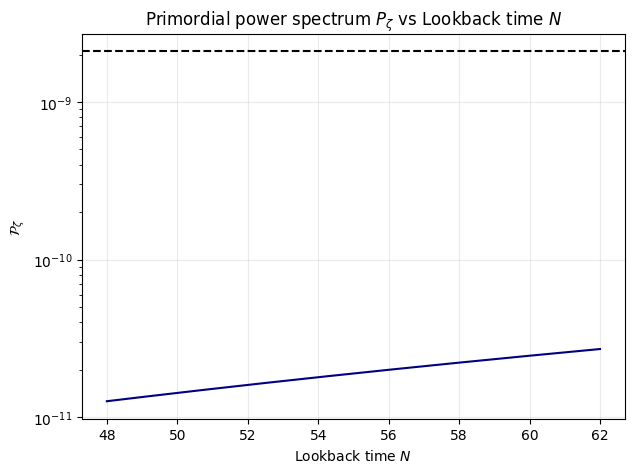

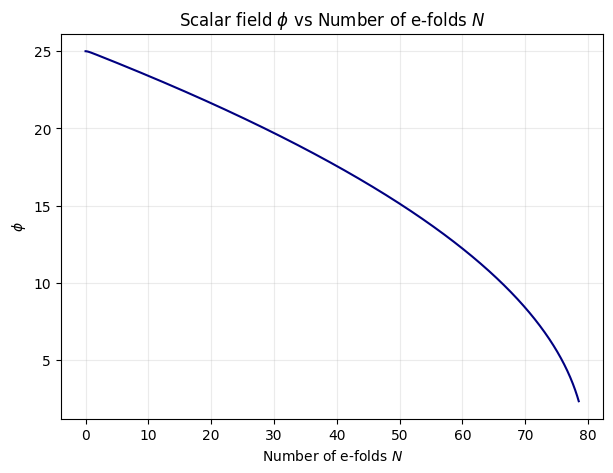

In [13]:
#Sample e-fold range
N_vals = np.linspace(N_end-62,N_end-48, 1000)
P_zeta_vals = []  #Store power spectrum values

#Evaluate spectrum at each point
for N in N_vals:
    phi, pi = sol.sol(N)
    phi = float(phi)
    pi = float(pi)

    epsilon = 0.5 * pi**2 #Compute slow-roll parameter
    if epsilon <= 0:
        P_zeta_vals.append(np.nan)
        continue

    V = model.V(phi)
    denom = 3.0 - epsilon
    if denom <= 0:
        P_zeta_vals.append(np.nan)
        continue

    H2 = V / denom
    P_zeta = H2 / (8.0 * np.pi**2 * epsilon)  #Compute curvature spectrum
    P_zeta_vals.append(P_zeta)
    
    
plt.rcParams["text.usetex"] = False
plt.figure(figsize=(7,5))  #Plot primordial spectrum 
plt.semilogy(N_end - N_vals, P_zeta_vals,color='navy')
plt.axhline(A_s, linestyle='--',color='black')
plt.xlabel(r"Lookback time $N$")
plt.ylabel(r"$\mathcal{P}_\zeta$")
plt.grid(True, which='major', alpha=0.25)
plt.title('Primordial power spectrum $P_\zeta$ vs Lookback time $N$')
plt.savefig("P_zeta_Quartic.pdf")

plt.show()

plt.figure(figsize=(7,5))
plt.plot(sol.t,sol.y[:1].T,color='navy')  #Plot phi (t)
plt.xlabel("Number of e-folds $N$")
plt.ylabel("$\phi$")
plt.title(r'Scalar field $\phi$ vs Number of e-folds $N$')
plt.grid(True, which='major', alpha=0.25)
plt.savefig("Phi_Quartic.pdf")
plt.show()


2.70709517071e-11
1.26276490048e-11


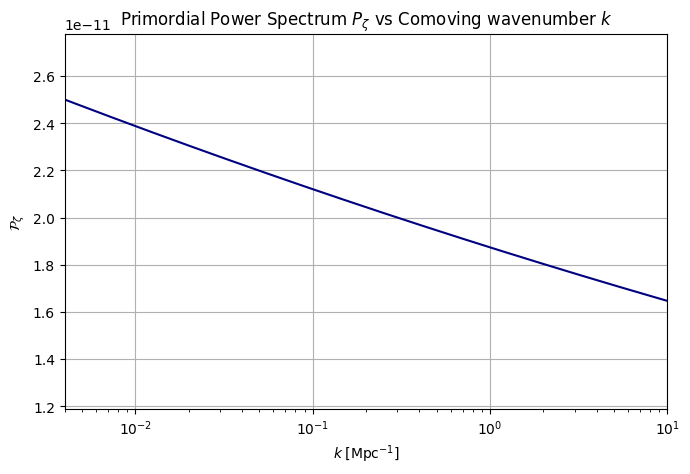

k_vals min, max: 0.000793784617114135 840.8943854351879
n_s (at N_end-50) = 0.93986961
n_s (at N_end-60) = 0.94987744


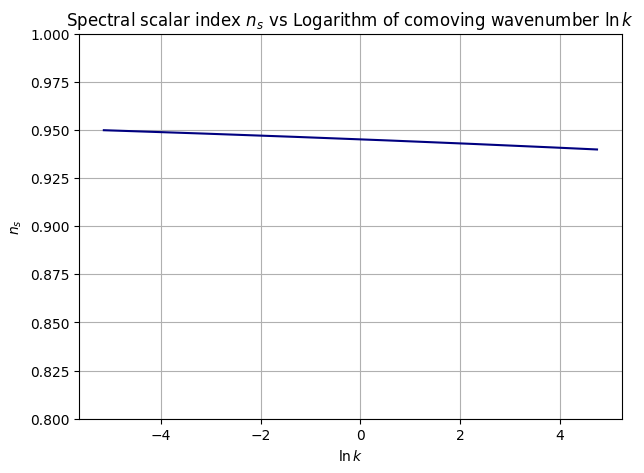

In [14]:
P_zeta_vals = np.array(P_zeta_vals)
N_vals = np.linspace(N_end-62,N_end-48,1000)  

print(f"{P_zeta_vals[0]:.12g}")
print(f"{P_zeta_vals[-1]:.12g}")

#Define constants+units
Mp = 1

SqrtG = (1/np.sqrt(8*np.pi)) * 1/Mp
meter = SqrtG/(1.61625518e-35)
kelvin = (1/SqrtG)/1.41678417e32
TCMB= 2.72548*kelvin
pc = 3.086e16 * meter
Mpc = pc * 10**6
m= 1e-5 * Mp
V_end = 1/2 * m**2 * phi_end**2

#Extract values for phi, pi at each sample point in the time grid
phis, pis = sol.sol(N_vals)

#Compute epsilon and V_cmb at each sample point in the time grid
m2 = m * m
epsilons = np.empty_like(N_vals)
Vs = np.empty_like(N_vals)
lnk = np.empty_like(N_vals)

pi2 = np.pi * np.pi
matching_eq_const_piece = (
        + (1/4.0) * np.log(pi2/135.0)
        + np.log(Mpc*Mp)
        + np.log(TCMB/Mp)
)

#Compute comoving wavenumber
for i in range(0, len(N_vals)):
    N_val = N_vals[i]

    phi = phis[i]
    pi = pis[i]

    phi2 = phi*phi
    pi2 = pi*pi

    epsilon = pi2 / (2.0 * Mp**2)
    V = (1.0/2.0) * m2 * phi2

    epsilons[i] = epsilon
    Vs[i] = V

    lnk[i] = (
        -(N_end-N_val)
        + matching_eq_const_piece
        + 1/4.0 * np.log((V/Mp**4)/(1.0-(epsilon/3.0)))
        + 1/4.0 * np.log((V/V_end) * (2.0/3.0)/(1.0-(epsilon/3.0)))
)

#k_vals measured in 1/Mpc, convert log - scale to k
k_vals = np.exp(lnk)


plt.figure(figsize=(7,5))  #Plot p_zeta(k)
plt.plot(k_vals, P_zeta_vals,color='navy')
plt.xlabel(r'$k\;[\mathrm{Mpc}^{-1}]$')
plt.ylabel(r'$\mathcal{P}_\zeta$')
plt.title(r'Primordial Power Spectrum $P_\zeta$ vs Comoving wavenumber $k$')
plt.grid(True)
plt.xscale("log")
plt.xlim((0.004,10))
plt.tight_layout()
plt.savefig("Pzeta_vs_k_Quartic.pdf")
plt.show()


print("k_vals min, max:", np.min(k_vals), np.max(k_vals))

lnk = np.log(k_vals)
lnP = np.log(P_zeta_vals)

#Sort data for spline fit
idx = np.argsort(lnk)

lnk_sorted = lnk[idx]
lnP_sorted = lnP[idx]

from scipy.interpolate import make_interp_spline

#Construct interpolation spline
spline = make_interp_spline(lnk_sorted, lnP_sorted, k=3) 

#Differentiate logarithmic spectrum
spline_deriv = spline.derivative()

#Select an observable window
mask = (N_vals >= N_end-60) & (N_vals <= N_end-50) 

lnk_region = lnk[mask]
ns_region = 1.0 + spline_deriv(lnk_region)  #Compute scalar spectral index

print(f"n_s (at N_end-50) = {ns_region[-1]:.8g}")
print(f"n_s (at N_end-60) = {ns_region[0]:.8g}")

plt.figure(figsize=(7,5))

plt.plot(lnk_region, ns_region,color='navy')  #Plot lnk vs ns

plt.xlabel(r'$\ln k$')
plt.ylabel(r'$n_s$')
plt.title('Spectral scalar index $n_s$ vs Logarithm of comoving wavenumber $\ln k$')

plt.ylim(0.8,1.0)

plt.grid(True)
plt.savefig("ns_vs_k_Quartic.pdf")
plt.show()


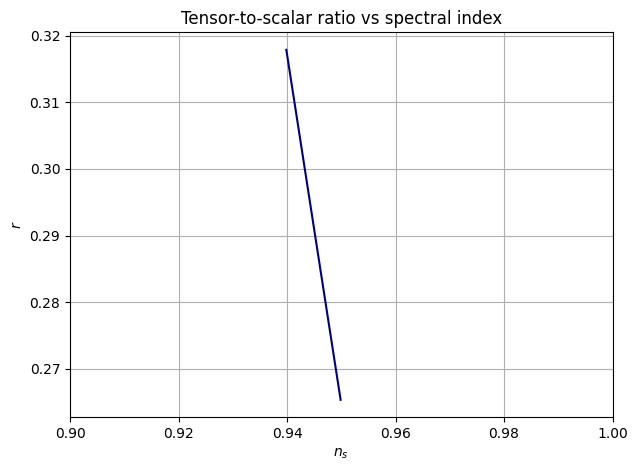

In [16]:
#Evaluate tensor-to-scalar ratio
phi_vals, pi_vals = sol.sol(N_vals)
epsilon_vals = pi_vals**2 / (2 * Mp**2)
r_vals = 16 * epsilon_vals

#Restrict r_vals to the observable window
mask = (N_vals >= N_end-60) & (N_vals <= N_end-50)

r_region = r_vals[mask]

#Plot numerical trajectory
plt.figure(figsize=(7,5))

plt.plot(ns_region, r_region,color='navy')

plt.xlabel(r'$n_s$')
plt.ylabel(r'$r$')
plt.title('Tensor-to-scalar ratio vs spectral index')
plt.xlim(0.9,1.0)
plt.grid(True)
plt.show()